# Preprocesamiento - Rendimiento Académico

El preprocesamiento se implementa con programación orientada a objetos: todos los pasos están en la clase `Preprocesador` (`src/data_prep.py`) y los parámetros fijos en `src/config.py`. Este notebook crea un objeto de esa clase y ejecuta cada paso con sus métodos. La misma clase la reutiliza la API para preparar los datos de un estudiante nuevo.

# 1.Importación librerías

In [1]:
import sys
sys.path.append('..') #para poder importar la carpeta src desde notebooks/

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_prep import Preprocesador

In [2]:
#Creamos el objeto que va a realizar todo el preprocesamiento
prep = Preprocesador()

# 2.Importación fuente de datos

## 2.1 Unión de las dos materias

In [3]:
#Lee student-mat.csv y student-por.csv, agrega la columna materia y los une
prep.cargar_datos()
prep.df.shape

(1044, 34)

In [4]:
prep.df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,materia
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,4,1,1,3,6,5,6,6,matematicas
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,3,1,1,3,4,5,5,6,matematicas
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,2,2,3,3,10,7,8,10,matematicas
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,2,1,1,5,2,15,14,15,matematicas
4,GP,F,16,U,GT3,T,3,3,other,other,...,3,2,1,2,5,4,6,10,10,matematicas


# 3.Análisis de Datos (EDA) + Preprocesado

## 3.1 Limpieza inicial

In [5]:
prep.df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1044 entries, 0 to 1043
Data columns (total 34 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      1044 non-null   str  
 1   sex         1044 non-null   str  
 2   age         1044 non-null   int64
 3   address     1044 non-null   str  
 4   famsize     1044 non-null   str  
 5   Pstatus     1044 non-null   str  
 6   Medu        1044 non-null   int64
 7   Fedu        1044 non-null   int64
 8   Mjob        1044 non-null   str  
 9   Fjob        1044 non-null   str  
 10  reason      1044 non-null   str  
 11  guardian    1044 non-null   str  
 12  traveltime  1044 non-null   int64
 13  studytime   1044 non-null   int64
 14  failures    1044 non-null   int64
 15  schoolsup   1044 non-null   str  
 16  famsup      1044 non-null   str  
 17  paid        1044 non-null   str  
 18  activities  1044 non-null   str  
 19  nursery     1044 non-null   str  
 20  higher      1044 non-null   str  
 21  in

In [6]:
#Valores nulos por columna
prep.revisar_nulos()

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
materia       0
dtype: int64

In [7]:
#Filas duplicadas
prep.revisar_duplicados()

np.int64(0)

In [8]:
prep.df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
age,1044.0,16.726054,1.239975,15.0,16.0,17.0,18.0,22.0
Medu,1044.0,2.603448,1.124907,0.0,2.0,3.0,4.0,4.0
Fedu,1044.0,2.387931,1.099938,0.0,1.0,2.0,3.0,4.0
traveltime,1044.0,1.522989,0.731727,1.0,1.0,1.0,2.0,4.0
studytime,1044.0,1.970307,0.834353,1.0,1.0,2.0,2.0,4.0
failures,1044.0,0.264368,0.656142,0.0,0.0,0.0,0.0,3.0
famrel,1044.0,3.935824,0.933401,1.0,4.0,4.0,5.0,5.0
freetime,1044.0,3.201149,1.031507,1.0,3.0,3.0,4.0,5.0
goout,1044.0,3.156130,1.152575,1.0,2.0,3.0,4.0,5.0
Dalc,1044.0,1.494253,0.911714,1.0,1.0,1.0,2.0,5.0


In [9]:
#Estudiantes con nota final 0 y con muchas faltas
prep.revisar_casos_extremos().head(10)

Estudiantes con G3 = 0: 53
Por materia: {'matematicas': 38, 'portugues': 15}
Con absences = 0: 53
Con G2 = 0: 20
Estudiantes con 30 o más faltas: 8


,materia,absences,G1,G2,G3
128,matematicas,0,7,4,0
130,matematicas,0,12,0,0
131,matematicas,0,8,0,0
134,matematicas,0,9,0,0
135,matematicas,0,11,0,0
136,matematicas,0,10,0,0
137,matematicas,0,4,0,0
140,matematicas,0,7,9,0
144,matematicas,0,5,0,0
146,matematicas,0,6,7,0


**Hallazgos de la limpieza inicial**

- No hay valores nulos ni filas duplicadas en los 1044 registros.
- Los rangos de las variables son coherentes (notas entre 0 y 20).
- Hay 53 estudiantes con G3 = 0 (38 de matemáticas y 15 de portugués). Todos tienen 0 faltas y 20 tienen también G2 = 0.
- Hay 8 estudiantes con 30 o más faltas (el máximo es 75).
- Decisión: por ahora no se eliminan estos casos, porque representan estudiantes en riesgo alto que el modelo debe aprender a detectar.

### Validación de categorías y rangos


In [10]:
#Valores únicos de cada columna de texto para detectar errores de escritura o categorías inesperadas
prep.validar_categorias()

school ['GP', 'MS']
sex ['F', 'M']
address ['U', 'R']
famsize ['GT3', 'LE3']
Pstatus ['A', 'T']
Mjob ['at_home', 'health', 'other', 'services', 'teacher']
Fjob ['teacher', 'other', 'services', 'health', 'at_home']
reason ['course', 'other', 'home', 'reputation']
guardian ['mother', 'father', 'other']
schoolsup ['yes', 'no']
famsup ['no', 'yes']
paid ['no', 'yes']
activities ['no', 'yes']
nursery ['yes', 'no']
higher ['yes', 'no']
internet ['no', 'yes']
romantic ['no', 'yes']
materia ['matematicas', 'portugues']


Todas las columnas de texto contienen únicamente las categorías indicadas en el diccionario de datos, sin errores de escritura ni valores inesperados.

In [11]:
#Rangos válidos de cada variable numérica según el diccionario de datos (definidos en config.py)
prep.validar_rangos()

age - rango 15 a 22 - valores fuera de rango: 0
Medu - rango 0 a 4 - valores fuera de rango: 0
Fedu - rango 0 a 4 - valores fuera de rango: 0
traveltime - rango 1 a 4 - valores fuera de rango: 0
studytime - rango 1 a 4 - valores fuera de rango: 0
failures - rango 0 a 4 - valores fuera de rango: 0
famrel - rango 1 a 5 - valores fuera de rango: 0
freetime - rango 1 a 5 - valores fuera de rango: 0
goout - rango 1 a 5 - valores fuera de rango: 0
Dalc - rango 1 a 5 - valores fuera de rango: 0
Walc - rango 1 a 5 - valores fuera de rango: 0
health - rango 1 a 5 - valores fuera de rango: 0
absences - rango 0 a 93 - valores fuera de rango: 0
G1 - rango 0 a 20 - valores fuera de rango: 0
G2 - rango 0 a 20 - valores fuera de rango: 0
G3 - rango 0 a 20 - valores fuera de rango: 0


Todas las variables numéricas se encuentran dentro de los rangos indicados en el diccionario de datos. No se detectaron valores inválidos, por lo que no es necesario corregir ni eliminar registros.

**Limitación conocida: estudiantes repetidos**

Aproximadamente 382 estudiantes cursan ambas materias (matemáticas y portugués), por lo que aparecen dos veces en el dataset unificado, una fila por materia, con los mismos datos personales y familiares.

Al dividir los datos en entrenamiento y prueba de forma aleatoria, un mismo estudiante puede quedar en ambos conjuntos. Esto podría hacer que las métricas de los modelos sean ligeramente más optimistas de lo real. Se decidió mantener todos los registros para no perder datos, dejando documentada esta limitación.


## 3.3 Limpieza final

### 3.3.1 Creación de variables derivadas (Feature engineering)

In [12]:
#Promedio de las notas parciales (G1 y G2) y tasa de ausencias (faltas / 93)
#IMPORTANTE: promedio_notas usa G1 y G2, por tanto en el Modelo 1 'sin G1/G2' también se debe eliminar
prep.crear_variables_derivadas()

,G1,G2,promedio_notas,absences,tasa_ausencias
0,5,6,5.5,6,0.064516
1,5,5,5.0,4,0.043011
2,7,8,7.5,10,0.107527
3,15,14,14.5,2,0.021505
4,6,10,8.0,4,0.043011


### 3.3.2 Creación de la variable objetivo del Modelo 2 (Nivel de riesgo)

In [13]:
#Crea nivel_riesgo a partir de G3 con el método calcular_nivel_riesgo
#Verificar si hay una proporción equilibrada entre los diferentes valores de la variable objetivo
prep.crear_nivel_riesgo()

nivel_riesgo
1    294
2    216
3    304
4    230
Name: count, dtype: int64

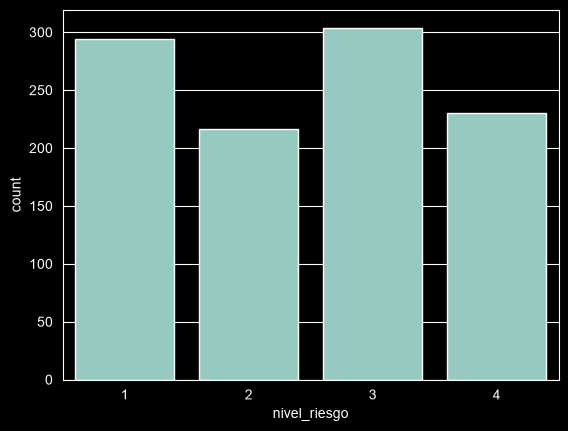

In [14]:
sns.countplot(x='nivel_riesgo',data=prep.df)
plt.show()

**Criterio del nivel de riesgo**

El dataset no incluye una variable de nivel de riesgo, por lo que se construye a partir de la nota final G3 (escala 0 a 20). En el sistema educativo portugués la nota mínima para aprobar es 10.

| Nivel | Rango G3 | Significado |
|---|---|---|
| 1 | 14 - 20 | Sin riesgo |
| 2 | 12 - 13 | Riesgo bajo |
| 3 | 10 - 11 | Riesgo medio (aprueba por poco) |
| 4 | 0 - 9 | Riesgo alto (reprueba) |

A mayor valor, mayor riesgo. Con estos rangos las cuatro clases quedan equilibradas (294, 216, 304 y 230 estudiantes), lo cual favorece el entrenamiento del modelo de clasificación multiclase.

### 3.3.3 Transformación variables categóricas

In [15]:
#Transforma las columnas de texto en columnas dummy (0 y 1)
prep.transformar_categoricas()

(1044, 64)

In [16]:
prep.df_post.head()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,nursery_no,nursery_yes,higher_no,higher_yes,internet_no,internet_yes,romantic_no,romantic_yes,materia_matematicas,materia_portugues
0,18,4,4,2,2,0,4,3,4,1,...,0,1,0,1,1,0,1,0,1,0
1,17,1,1,1,2,0,5,3,3,1,...,1,0,0,1,0,1,1,0,1,0
2,15,1,1,1,2,3,4,3,2,2,...,0,1,0,1,0,1,1,0,1,0
3,15,4,2,1,3,0,3,2,2,1,...,0,1,0,1,0,1,0,1,1,0
4,16,3,3,1,2,0,4,3,2,1,...,0,1,0,1,1,0,1,0,1,0


In [17]:
#Correlación de las variables con la nota final G3
prep.correlacion_con_g3()

nivel_riesgo          -0.868410
failures              -0.383145
higher_no             -0.236578
materia_matematicas   -0.187166
Dalc                  -0.129642
                         ...   
higher_yes             0.236578
G1                     0.809142
promedio_notas         0.894479
G2                     0.910743
G3                     1.000000
Name: G3, Length: 64, dtype: float64

**Observaciones de la correlación con G3**

- Las variables más relacionadas con la nota final son G2, G1 y promedio_notas (positivas) y failures (negativa).
- Sin las notas parciales, las variables con mayor relación son failures, higher_no y materia_matematicas, lo que anticipa que el Modelo 1 sin G1/G2 tendrá un desempeño menor.
- nivel_riesgo se deriva de G3, por lo que no debe usarse como variable de entrada en el Modelo 1.

# 4.Train Test Split

In [18]:
#Separa X e y (G3 y nivel_riesgo) y divide 80% entrenamiento / 20% prueba
prep.dividir()

((835, 62), (209, 62))

# 5.Escalado

In [19]:
#MinMaxScaler ajustado SOLO con los datos de entrenamiento
prep.escalar()

(np.float64(1.0), np.float64(0.0))

# 6.Guardar datos procesados

- `data/processed/train.csv` y `test.csv`: datos limpios con dummies, **sin escalar**, incluyen G3 y nivel_riesgo. Cada modelo elimina las columnas que no utiliza (por ejemplo G1, G2 y promedio_notas en el Modelo 1 sin notas parciales) y aplica su escalado.
- `models/scaler.pkl`: MinMaxScaler entrenado con todas las variables de entrada.
- `models/columnas.pkl`: columnas finales tras get_dummies (las necesita la API para preparar los datos nuevos).

In [20]:
#Guarda train.csv, test.csv, scaler.pkl y columnas.pkl
prep.guardar()

((835, 64), (209, 64))

In [21]:
#Verificamos que los archivos se guardaron correctamente
pd.read_csv('../data/processed/train.csv').head()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,higher_no,higher_yes,internet_no,internet_yes,romantic_no,romantic_yes,materia_matematicas,materia_portugues,G3,nivel_riesgo
0,16,3,3,1,2,0,4,3,2,1,...,0,1,1,0,1,0,0,1,13,2
1,15,3,2,1,2,0,4,2,2,1,...,0,1,0,1,1,0,1,0,19,1
2,16,4,3,1,2,0,5,4,2,1,...,0,1,0,1,1,0,0,1,13,2
3,16,2,3,1,2,0,2,3,1,1,...,0,1,0,1,1,0,0,1,14,1
4,17,1,1,3,1,1,5,2,1,1,...,0,1,0,1,0,1,1,0,0,4
